# Credit Risk & Financial Inclusion Study

**Question:** Which factors are associated with loan default, and how can a lender evaluate
underserved customers fairly?

This notebook walks through the five steps of the project. Each step calls the functions
in `src/`, so the notebook and the scripts always give the same results
(`python src/run_all.py` runs everything without the notebook).

**Data:** Statlog German Credit (UCI), 1,000 loans, 30% bad credits.
**Important:** the code table that comes with the data is wrong for 8 variables.
We use the corrected table of Grömping (2019). The data are from 1973-1975, and bad credits
were deliberately oversampled (real default rate about 5%).

> The results describe patterns in old historical data. They do **not** prove that
> any person is or is not creditworthy.

In [1]:
%matplotlib inline
import sys, importlib
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import common as C

pd.set_option("display.max_colwidth", 60)
step = {name: importlib.import_module(name) for name in
        ["01_data_prep", "02_statistics", "03_model", "04_shap", "05_fairness"]}

def show(name, width=650):
    display(Image(filename=str(C.FIG_DIR / name), width=width))

def table(name):
    return pd.read_csv(C.TABLE_DIR / name)

## Step 1 - Data preparation and SQL

We load the raw file, replace codes such as `A11` with readable labels, store the table
in a SQLite database and answer simple questions with SQL.

In [2]:
df = C.load_data()
print(df.shape)
df.head()

(1000, 22)


,checking_status,duration_months,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,...,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,default,age_group
0,no checking account,6,all credits at this bank paid back duly,furniture / equipment,1169,>= 1000 DM,>= 7 years,< 20% of income,male: married / widowed,none,...,67,none,rent,2,skilled employee,1,yes,no,0,> 25
1,< 0 DM,48,no credits taken / all paid back duly,furniture / equipment,5951,unknown / no savings account,1 to 4 years,25 to 35% of income,female non-single OR male single,none,...,22,none,rent,1,skilled employee,1,no,no,1,<= 25
2,>= 200 DM or salary account,12,all credits at this bank paid back duly,repairs,2096,unknown / no savings account,4 to 7 years,25 to 35% of income,male: married / widowed,none,...,49,none,rent,1,unskilled resident,2,no,no,0,> 25
3,no checking account,42,no credits taken / all paid back duly,car (used),7882,unknown / no savings account,4 to 7 years,25 to 35% of income,male: married / widowed,guarantor,...,45,none,own,1,skilled employee,2,no,no,0,> 25
4,no checking account,24,existing credits paid back duly,others,4870,unknown / no savings account,1 to 4 years,20 to 25% of income,male: married / widowed,none,...,53,none,own,2,skilled employee,2,no,no,1,> 25


In [3]:
step["01_data_prep"].main()

STEP 1 - Data preparation and SQL
Loaded 1000 clients and 22 columns.



-- sql_01_overall
 n_clients  n_defaults  default_rate_pct
      1000         300              30.0

-- sql_02_by_checking_status
            checking_status   n  default_rate_pct
        no checking account 274              49.3
                     < 0 DM 269              39.0
                0 to 200 DM  63              22.2
>= 200 DM or salary account 394              11.7

-- sql_03_by_credit_history
                         credit_history   n  default_rate_pct
        delay in paying off in the past  40              62.5
   critical account / credits elsewhere  49              57.1
  no credits taken / all paid back duly 530              31.9
        existing credits paid back duly  88              31.8
all credits at this bank paid back duly 293              17.1

-- sql_04_by_purpose
              purpose   n  default_rate_pct
              repairs  50              44.0
               others 234              38.0
  domestic appliances  22              36.4
           retrainin

**Reading:** clients with no checking account (49%) or a negative balance (39%) default much
more often than clients with at least 200 DM (12%). Young clients (19-25) default more
often (42%) than older ones.

## Step 2 - Statistical analysis (Q1: which factors?)

- **Chi-square test + Cramér's V** for categorical variables (V from 0 = no link to 1 = perfect link).
- **Mann-Whitney U + rank-biserial r** for numeric variables (no normality assumption).
- **Bonferroni correction**, because we run 20 tests.
- **Logistic regression** to see each factor "all other things being equal" (odds ratios).

In [4]:
step["02_statistics"].main()

STEP 2 - Statistical analysis

Univariate tests (sorted by effect size):
               variable  effect_measure  effect_size  p_bonferroni
        checking_status      Cramer's V        0.352  2.437804e-25
        duration_months rank-biserial r        0.257  1.596333e-09
         credit_history      Cramer's V        0.248  2.558375e-11
                savings      Cramer's V        0.190  5.522428e-06
                purpose      Cramer's V        0.183  2.314982e-03
               property      Cramer's V        0.154  5.716883e-04
                    age rank-biserial r       -0.141  7.825547e-03
             employment      Cramer's V        0.136  2.090905e-02
                housing      Cramer's V        0.135  2.233493e-03
other_installment_plans      Cramer's V        0.113  3.258636e-02
          credit_amount rank-biserial r        0.110  1.183522e-01
    personal_status_sex      Cramer's V        0.098  4.447601e-01
          other_debtors      Cramer's V        0.082  7.

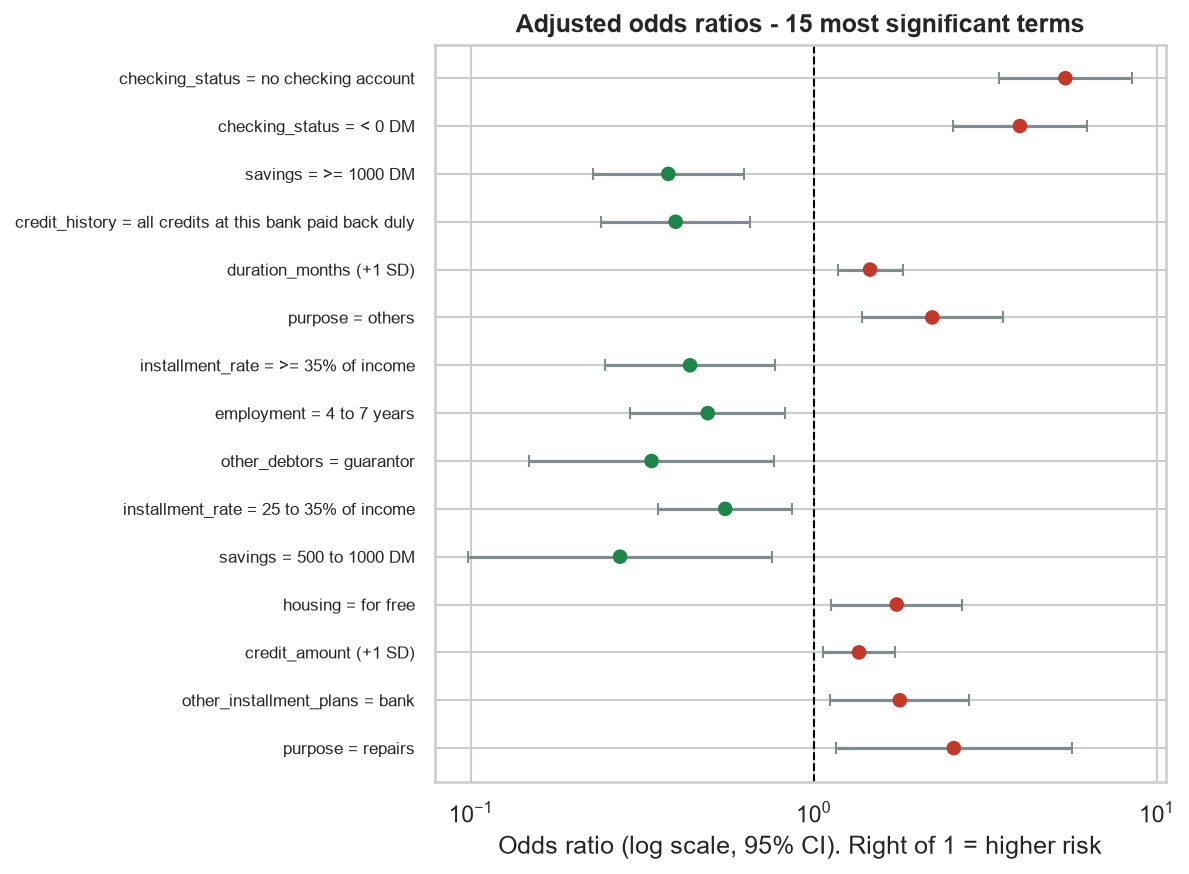

In [5]:
show("stats_odds_ratios.png")

**Reading:** checking account status, credit history, loan duration and savings are the
strongest factors. Some results are surprising (e.g. a high installment-to-income ratio goes
with *fewer* defaults). A likely reason is selection: the bank only gave such loans to clients
it trusted. This is why we speak of **associations, not causes**.

## Step 3 - Model, threshold and risk segmentation (Q2 and Q3)

- Logistic regression **without** sex, age and foreign-worker status.
- **Class imbalance:** a "balanced" model gives the same ranking but inflated probabilities.
  We keep the normal model and handle the imbalance with the threshold instead.
- **Threshold:** with costs 5 (approve a defaulter) and 1 (reject a good client), decision
  theory says: reject when P(default) ≥ 1/(1+5) = 0.167.

In [6]:
step["03_model"].main()

STEP 3 - Model, threshold and segmentation



Normal vs balanced model (5-fold CV on training set):
   model  roc_auc  mean_predicted_pd  observed_default_rate  brier_score
  normal    0.759              0.300                    0.3        0.176
balanced    0.758              0.435                    0.3        0.200

Threshold from the cost matrix: 0.167 | best on training CV: 0.16


Test ROC-AUC = 0.796

Strategies on the test set:
              strategy  approval_rate  good_clients_approved  defaulters_approved  expected_cost  saving_vs_best_simple_rule
      approve everyone          1.000                  1.000                1.000          1.500                      -1.143
       reject everyone          0.000                  0.000                0.000          0.700                       0.000
 model, threshold 0.50          0.736                  0.863                0.440          0.756                      -0.080
model, threshold 0.167          0.396                  0.509                0.133          0.544                       0.223

Approval rate at threshold 1/6 under the sample vs the real default rate:
 default_rate_assumed  approval_rate
                 0.30          0.396
                 0.05          0.872



Risk bands:
            band   n  default_rate  ci_low  ci_high                                suggested_action
 A (lowest risk) 200         0.065   0.038    0.108                         approve, standard terms
               B 200         0.140   0.099    0.195                         approve, standard terms
               C 200         0.270   0.213    0.335 approve with smaller amount or shorter duration
               D 200         0.400   0.335    0.469           manual review (guarantor, collateral)
E (highest risk) 200         0.625   0.556    0.689                    decline or secured loan only


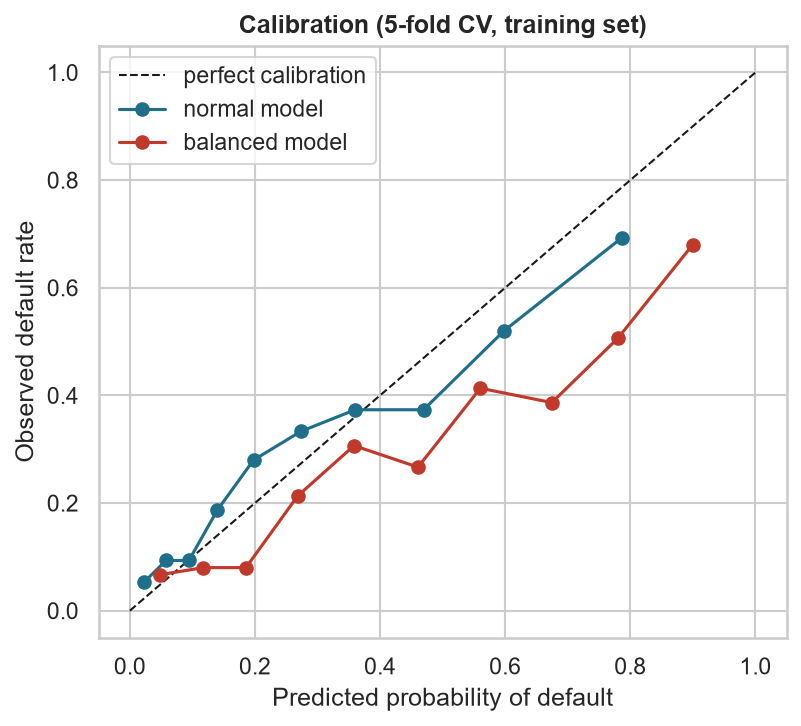

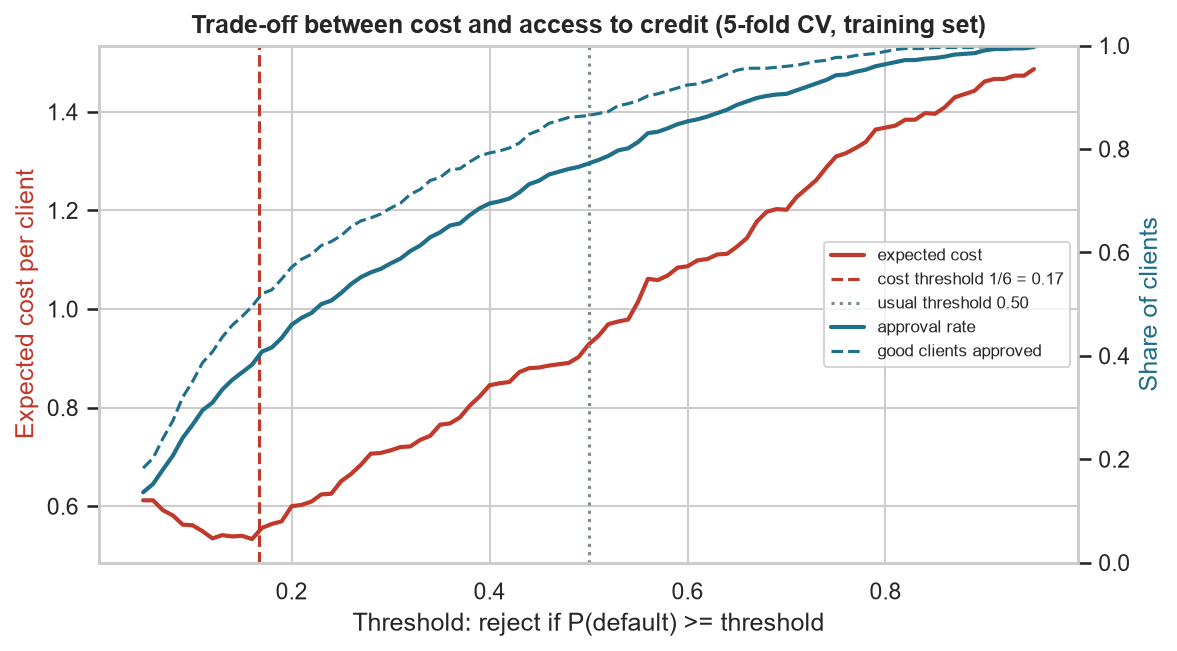

In [7]:
show("model_calibration.png", 450)
show("model_threshold_tradeoff.png")

**Reading:** at the usual threshold of 0.50 the model costs *more* than simply rejecting
everyone. At 1/6 it saves about 22% compared with the best simple rule, but it approves only
about 40% of applicants and refuses about half of the good clients. That is the price of the
5:1 cost ratio in a sample with 30% bad credits. With the real default rate (about 5%) the same
threshold would approve about 87% of applicants.

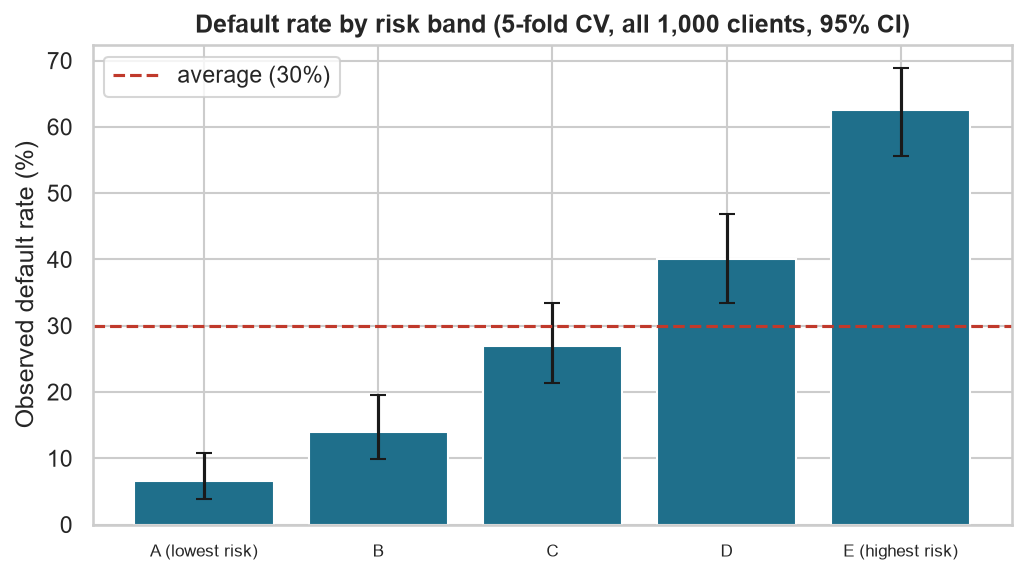

,band,n,defaults,mean_score,min_score,max_score,default_rate,ci_low,ci_high,suggested_action
0,A (lowest risk),200,13,0.043,0.006,0.076,0.065,0.038,0.108,"approve, standard terms"
1,B,200,28,0.121,0.076,0.166,0.140,0.099,0.195,"approve, standard terms"
2,C,200,54,0.234,0.167,0.311,0.270,0.213,0.335,approve with smaller amount or shorter duration
3,D,200,80,0.420,0.312,0.539,0.400,0.335,0.469,"manual review (guarantor, collateral)"
4,E (highest risk),200,125,0.687,0.540,0.973,0.625,0.556,0.689,decline or secured loan only


In [8]:
show("model_risk_bands.png", 550)
table("model_risk_bands.csv")

## Step 4 - Explaining the model with SHAP

For a logistic regression, SHAP value = coefficient × (client value − average value).
The script checks this formula. SHAP is useful to explain *one* decision to *one* client.

In [9]:
step["04_shap"].main()

STEP 4 - SHAP explanations
Max difference SHAP vs formula: 0.00e+00
                                                 feature  mean_abs_shap
           checking_status = >= 200 DM or salary account          0.432
credit_history = all credits at this bank paid back duly          0.340
                  savings = unknown / no savings account          0.334
                                         duration_months          0.283
                   checking_status = no checking account          0.254
                                           credit_amount          0.205
                      installment_rate = < 20% of income          0.202
                               employment = 4 to 7 years          0.187
                                      housing = for free          0.167
                                  property = real estate          0.157


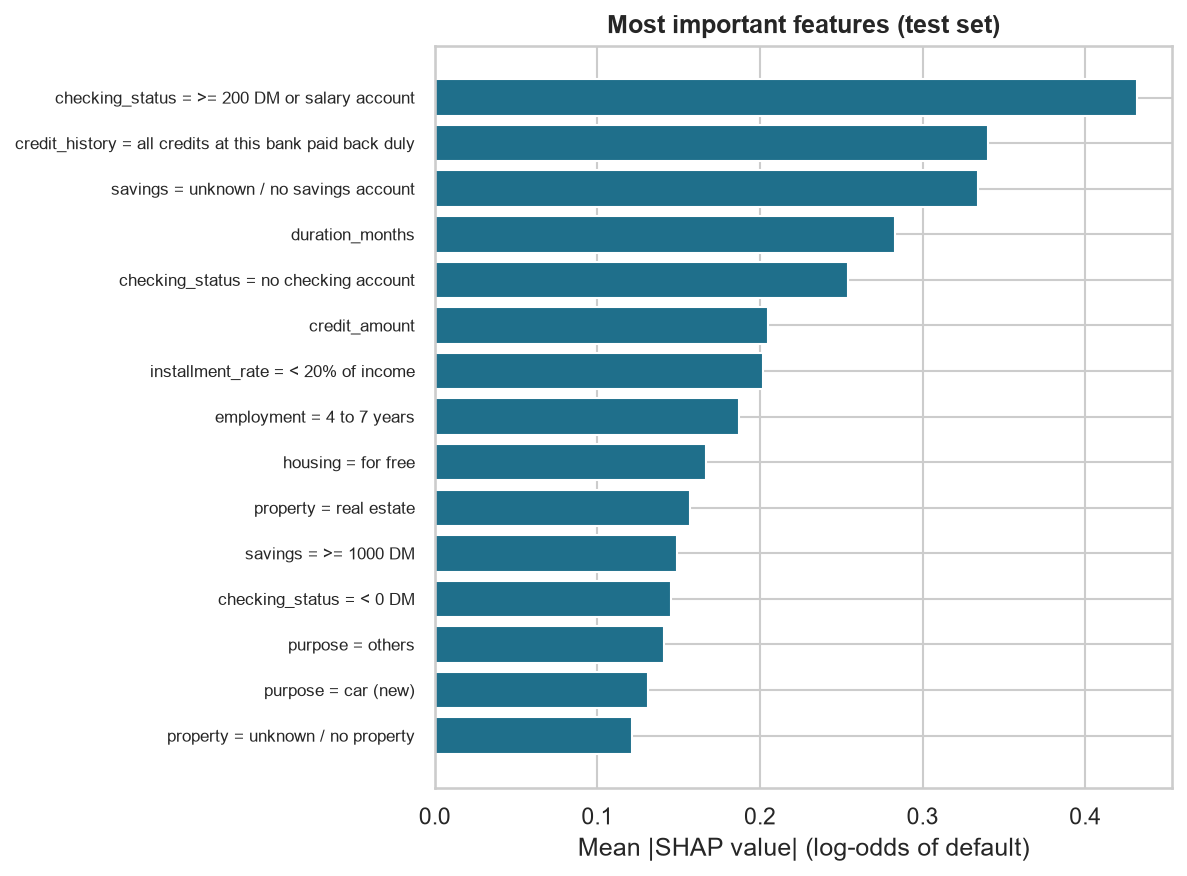

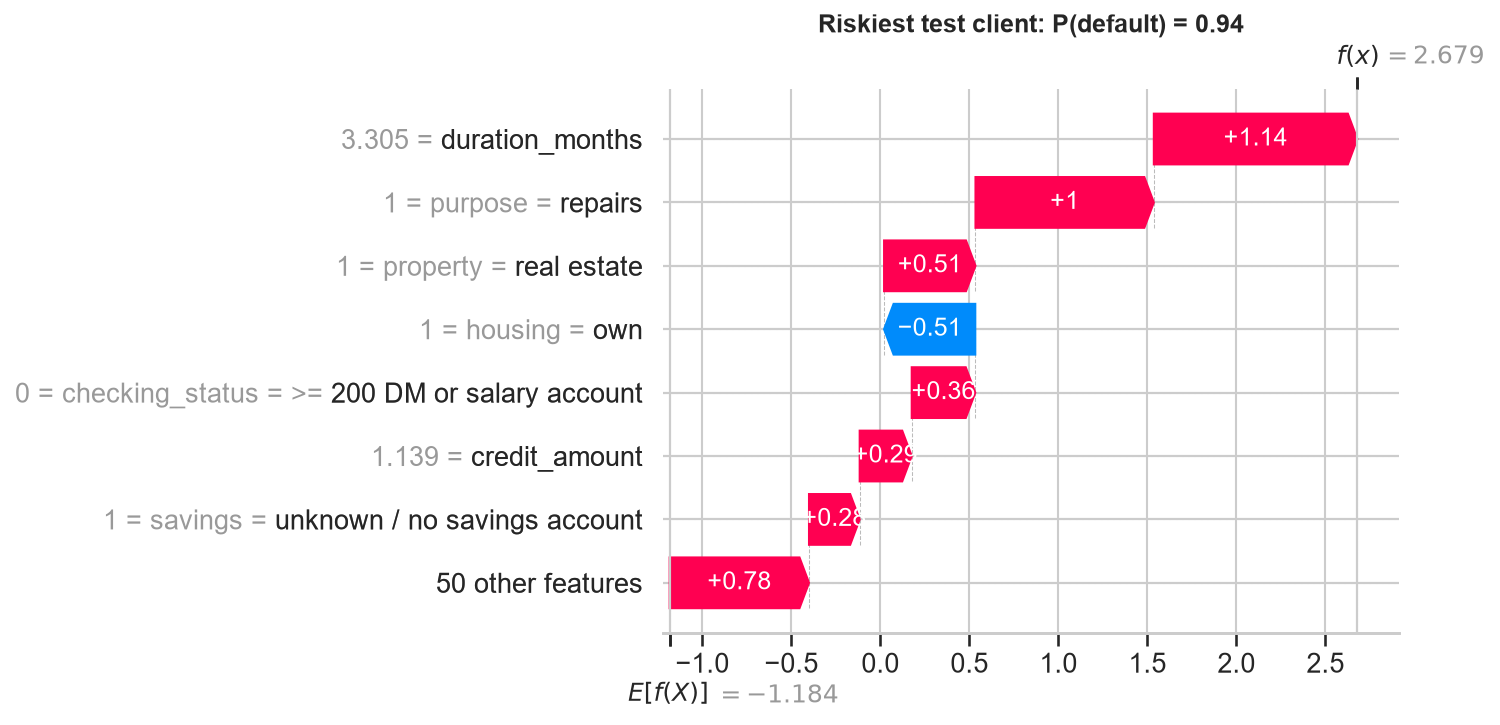

In [10]:
show("shap_importance.png")
show("shap_waterfall_riskiest.png")

## Step 5 - Fairness audit (Q4)

We compare approval rates between groups using cross-validated scores for all 1,000 clients,
with 95% bootstrap confidence intervals. Sex is **not** audited because it cannot be recovered
from the data (single men and non-single women share one code).

In [11]:
step["05_fairness"].main()

STEP 5 - Fairness audit


model  cv_roc_auc      attribute  n_protected  approval_protected  approval_reference  disparate_impact  di_ci_low  di_ci_high  equal_opportunity_gap  eo_gap_ci_low  eo_gap_ci_high
blind       0.775      age_group          190               0.279               0.428             0.651      0.499       0.809                 -0.123         -0.222          -0.023
blind       0.775 foreign_worker           37               0.432               0.399             1.084      0.706       1.500                 -0.029         -0.196           0.148
 full       0.778      age_group          190               0.247               0.448             0.552      0.416       0.704                 -0.183         -0.279          -0.080
 full       0.778 foreign_worker           37               0.730               0.398             1.835      1.431       2.212                  0.242          0.084           0.384


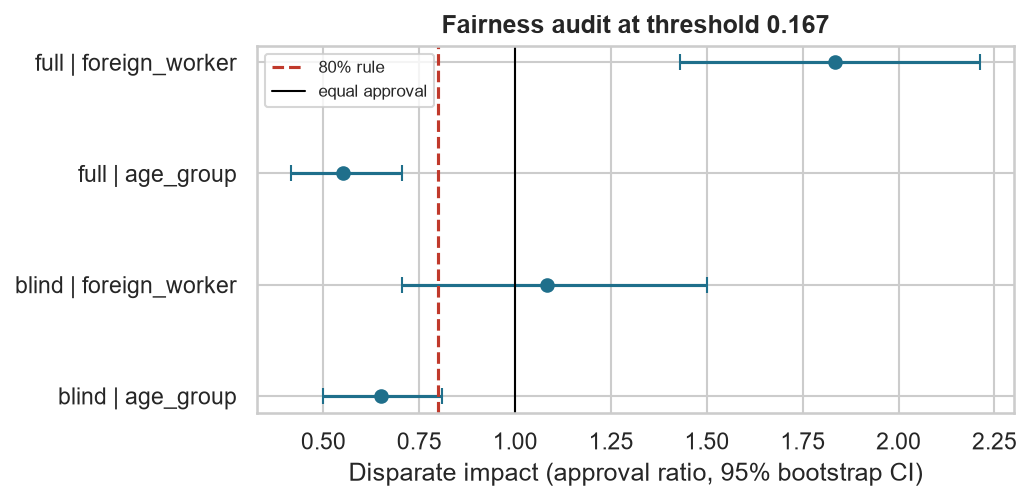

In [12]:
show("fairness_disparate_impact.png", 600)

**Reading:**
- **Age:** even without the age variable, clients aged 25 or less are approved much less
  often (disparate impact about 0.65, below the 80% rule), and good young payers are refused
  more often. Removing a sensitive variable does not remove the gap, because other variables
  (duration, savings, employment) are linked to age.
- **Foreign workers:** only 37 people, so the confidence interval is very wide. We cannot
  draw a reliable conclusion.

## Conclusion

A simple, transparent logistic regression separates risk well (test ROC-AUC about 0.80;
default rate from 6% in the safest band to 62% in the riskiest). The decision threshold is
a **business and social choice**, not only a technical one: it decides how many good
clients lose access to credit. Fairness must be **measured**, not assumed. See
`report/` for the full discussion and references.